In [1]:
%matplotlib inline
import warnings

import pandas as pd
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")


def show_table(df, floatfmt=".4f", index=False):
    display(Markdown(df.to_markdown(index=index, floatfmt=floatfmt)))

In [2]:
%%capture
%run main.py

# CQF Exam Three

**Machine Learning in Finance**

## Introduction

The objective of this exam is to develop a predictive framework to forecast positive market moves (uptrends) utilizing advanced ensemble gradient boosting techniques.

I chose State Street SPDR S&P 500 ETF Trust (SPY) which represents the largest and most actively traded ETFs in the world. It is designed to track performance of the S&P 500 index.

My target variable is labeled as $Y \in \{0, 1\}$, where 1 represents a sufficiently large positive daily market move of SPY to distinguish it from market fluctuations around zero-mean. The threshold for binary classification depends on most recent volatility $\sigma_t$ (the 20-day rolling standard deviation of daily log returns) multiplied by a scale factor $k$. Volatility scale $k$ is chosen as a hyperparameter, which in practice can be calibrated/tuned to achieve target performance in a given market regime. I chose $k=0.5$ which corresponds to approximate probability 30% of observing positive signal assuming normally distributed random variable. It also treats 40% of returns around zero mean as a market noise, which is grouped with the negative class.

$$
y_t =
\begin{cases}
1, & r_{t+1} > k\sigma_t \\
0, & r_{t+1} \leq k\sigma_t
\end{cases}
\qquad r_{t+1} = \ln\frac{C_{t+1}}{C_t}
$$

In this set-up we would long the shares of ETF if the model predicts more than 50% chance of the event $r_{t+1} > k\sigma_t$. The probability threshold 50% is also a model hyperparameter and can be selected based on conservatism of the trader. The larger this threshold is, the more conservative a trader might be.

The choice of initial feature pool is driven by common factors in technical analysis, e.g. past returns, volatilities, RSI, relative position in Bollinger Bands and so on. The full description is provided in Section Q1(b). All features have daily frequency.

The length of historical dataset should be aligned with observed data frequency. My data sample spans period from 2010-01-01 to today which covers roughly 17 years. I split data into train and test sample with 20% test size, which means train sample covers roughly 13.5 years from 2010 to mid-2023, leaving the remaining sample for testing. This period includes Covid-19 which means the model should be trained on both bull and bear markets.

In [3]:
sample_rows = []
for name, target in (("Train", data_engineering.y_train), ("Test", data_engineering.y_test)):
    sample_rows.append(
        {
            "Sample": name,
            "Start": target.index[0].date(),
            "End": target.index[-1].date(),
            "Years": (target.index[-1] - target.index[0]).days / 365.25,
            "Observations": len(target),
            "Positive labels, %": target.mean() * 100,
        }
    )
show_table(pd.DataFrame(sample_rows), floatfmt=".2f")

| Sample   | Start      | End        |   Years |   Observations |   Positive labels, % |
|:---------|:-----------|:-----------|--------:|---------------:|---------------------:|
| Train    | 2010-02-02 | 2023-06-06 |   13.34 |           3359 |                32.21 |
| Test     | 2023-06-07 | 2026-10-12 |    3.35 |            840 |                33.69 |

## Q1: Feature engineering

In this section I will examine feature selection techniques, feature transformations and selection criteria for each funnel method and finally I will list feature candidates for subsequent modelling exercise.

I focus on three representative feature selection techniques. I combine correlation analysis, Recursive Feature Elimination (RFE) and Random Forest as Filter, Wrapper and Embedded methods.

### (a) Feature selection funnel

Each method looks at different aspect of feature engineering.

#### Filter: correlation analysis

Filter selection methods represent a generic set of methods without model embedding assumption. In other words, we do not model explicitly how features interact to predict the target and do not select them based on their predictive power when looked at together. Instead, we either look at their individual power to predict the target, or multicollinearity, or joint correlations. Our ML classifier is a tree-based gradient boosting algorithm, which captures non-linear relationship between target and predictors. As such, individual relationship between features and target or multicollinearity is less practical than having a general idea of whether some features are relevant given presence of others. Hence, for this exercise I favor correlation analysis. Correlation analysis is performed after we prune missing data and non-stationary predictors. I set a correlation threshold of 0.9 which is generally not too punitive.

Once features are filtered after correlation analysis, I further prune them based on Wrapper and Embedded methods. I expect that two methods will select different sets of features therefore I allow for wide enough pool in each method by setting maximum number of predictors to 10 and then select top candidates based on overlapping subset from the two broad pools.

#### Wrapper: Recursive Feature Elimination

Wrapper methods evaluate a specific ML-algorithm to select candidate features. Each method has its own advantages and is expected to generate a unique pool of candidates. Since we allow for a broad pool of candidates before we further narrow it down, the goal is to set a contest with low selection bar in a single widely used ML technique. In this exercise we will stick to RFE.

RFE filters out predictors which have lower regression coefficients by magnitudes at each step. This technique requires feature standard scaling before fitting the model because units of changes of predictors should be comparable when we interpret the results. The method looks at different aspect of feature engineering answering the question: "how strongly a predictor changes the model's estimated odds of positive market move, holding other predictors constant?"

Assuming sigmoid function for probability estimation:

$$
P(y = 1 \mid X) = \frac{1}{1 + e^{-(\beta_{0} + \sum_{j=1}^{K}\beta_{j}X_{j})}}
$$

By maximizing the likelihood function using log-transformation:

$$
L = \prod_{i=1}^{N} P(y_{i} = 1 \mid X)^{y_{i}} \left(1 - P(y_{i} = 1 \mid X)\right)^{1 - y_{i}}
$$

We obtain logistic regression estimates:

$$
\log\left(\frac{p}{1 - p}\right) = \beta_{0} + \beta_{1}X_{1} + \dots + \beta_{K}X_{K}
$$

Where one unit increase of predictor $X_{j}$ multiplies the odds of positive signal by:

$$
OR_{j} = e^{\beta_{j}}
$$

#### Embedded: Random Forest

Unlike Wrapper methods, embedded methods embed features during model building process and selected candidate are monitored at each iteration of model training phase. Final selection is based on evaluation metric which incorporates fitting results of multiple fitted models. Since in the next chapter I will feed top candidates into gradient boosting algorithms capturing non-linear relationship, Random Forest will be a good starting point as a preliminary contest aiming at picking predictors doing well at predicting target together. At the same time, I set a high pass rate as I will further need to incorporate candidates from the Wrapper method as well.

Unlike logistic regression, Random Forest does not estimate coefficients $\beta_{j}$. Instead, each decision tree chooses feature splits that reduce node impurity. For classification, I use Gini impurity measure which equals for binary target:

$$
G(t) = 2p_{t}(1 - p_{t})
$$

The impurity reduction from splitting node $t$ is:

$$
\Delta G(t) = G(t) - \frac{n_{L}}{n_{t}}G(L) - \frac{n_{R}}{n_{t}}G(R)
$$

The importance of feature $X_{j}$ aggregates the weighted impurity reductions across all splits using that feature, averaged across trees and normalized.

$$
I_{j} \propto \sum_{\text{trees}} \sum_{t:\ \text{split on } j} \frac{n_{t}}{N}\Delta G(t)
$$

A feature with higher importance means it contributes more to distinguish market conditions with positive moves from noise and negative moves, allowing for nonlinear relationships and interactions between predictors.

### (b) Feature pool and stationarity

I start with downloading time series for Open, Close, High, Low and Volume for SPY index. Below I focus on common features in technical analysis such as momentum or relative position.

Assuming approximately white noise process for returns of prices or trading volume, defined as log returns or fractional price differences or percentage price changes, I form suitable feature pool as illustrated below. I include 5-day, 10-day and 15-day windows and originally have 26 features.

| N | Feature | Transformation | Economic interpretation |
|-----|----------|----------------------------------------|----------------------------------------|
| 1 | GAP | Gap up or down relative to the previous close. | Overnight repricing between sessions. |
| 2 | RET | Daily log return of close. | One-session proportional price movement. |
| 3-5 | PCHGX | Close percentage change over the window. Window = X. | Price momentum over the specified lookback. |
| 6-8 | VCHGX | Volume percentage change over the window. Window = X. | Change in trading activity over the specified lookback. |
| 9-11 | RETX | Rolling sum of daily log returns over the window. Window = X. | Cumulative log price movement over the lookback. |
| 12-14 | GAPX | Rolling mean of gaps. Window = X. | Average overnight repricing over the lookback. |
| 15-17 | STDX | Rolling standard deviation of daily log returns. Window = X. | Realized return volatility over the lookback. |
| 18-20 | BBX | Close position within the Bollinger bands, which use two standard deviations. Window = X. | Relative price position within the Bollinger envelope; values can fall outside 0 to 1. |
| 21-23 | RSIX | Relative Strength Index calculated over the window. Window = X. | Momentum oscillator on a 0 to 100 scale. |
| 24-26 | STOCHX | Stochastic oscillator over the window with smooth_window=1. Window = X. | Close location within the recent high-low range, on a 0 to 100 scale. |

The features are computed as follows:

$$
\begin{aligned}
GAP_t &= \frac{O_t}{C_{t-1}} - 1 \\
RET_t &= \ln\frac{C_t}{C_{t-1}} \\
PCHG_{X,t} &= \frac{C_t}{C_{t-X}} - 1 \\
VCHG_{X,t} &= \frac{V_t}{V_{t-X}} - 1 \\
RET_{X,t} &= \sum_{i=0}^{X-1} RET_{t-i} = \ln\frac{C_t}{C_{t-X}} \\
GAP_{X,t} &= \frac{1}{X}\sum_{i=0}^{X-1} GAP_{t-i} \\
STD_{X,t} &= \sqrt{\frac{1}{X-1}\sum_{i=0}^{X-1}\left(RET_{t-i} - \overline{RET}_{X,t}\right)^2} \\
BB_{X,t} &= \frac{C_t - LB_{X,t}}{UB_{X,t} - LB_{X,t}}, \quad LB_{X,t} = SMA_X(C)_t - 2\sigma_X(C)_t, \quad UB_{X,t} = SMA_X(C)_t + 2\sigma_X(C)_t \\
RSI_{X,t} &= 100 - \frac{100}{1 + RS_{X,t}}, \quad RS_{X,t} = \frac{AvgGain_{X,t}}{AvgLoss_{X,t}} \\
STOCH_{X,t} &= 100\,\frac{C_t - Lmin_{X,t}}{Hmax_{X,t} - Lmin_{X,t}}, \quad Hmax_{X,t} = \max_{i<X} H_{t-i}, \quad Lmin_{X,t} = \min_{i<X} L_{t-i}
\end{aligned}
$$

RSI inputs are the gains and losses of the close:

$$
Gain_t = \max(C_t - C_{t-1}, 0), \qquad Loss_t = \max(C_{t-1} - C_t, 0)
$$

$$
AvgGain_{X,t} = \frac{(X-1)\,AvgGain_{X,t-1} + Gain_t}{X}, \qquad AvgLoss_{X,t} = \frac{(X-1)\,AvgLoss_{X,t-1} + Loss_t}{X}
$$

Notation: $O_t$ = open; $C_t$ = close; $H_t$ = high; $L_t$ = low; $V_t$ = volume; $X$ = lookback window (trading days). $\sum$ is a sum over the $X$-day window; $SMA_X$ is its simple moving average. All return-type features (GAP, PCHG, VCHG, RET) are expressed as decimals, not percentages.

Notes: STDX uses sample standard deviation (ddof=1); BBX bands use price standard deviation, not return volatility. RSI uses the chosen gain/loss smoothing convention (e.g., Wilder). Guard against zero denominators and use consistent split-adjusted OHLC prices.

RSI note: AvgGain and AvgLoss use Wilder-style exponential smoothing ($\alpha = 1/X$), initialized from the first $X$ price changes. The stochastic oscillator parameter smooth_window=1 means no smoothing of %K; it does not change the RSI formula.

Stationarity is an important property of time series because non-stationary time series might perform well at predicting the target on training data by chance and due to unstable nature exhibit opposite behavior in a different regime making this relationship spurious. Therefore, I first run the Augmented Dickey–Fuller (ADF) and Kwiatkowski–Phillips–Schmidt–Shin (KPSS) tests and then prune the predictors when they fail at least one of the tests.

The ADF and KPSS tests are used to assess whether a time series is stationary. The tests have opposite null hypotheses.

**ADF test:**

$$
\Delta x_{t} = \alpha + \gamma x_{t-1} + \varphi \Delta x_{t-1} + \epsilon_{t}
$$

where $\Delta x_{t} = x_{t} - x_{t-1}$.

Hypotheses:

* $H_{0}: \gamma = 0$ — the series contains a unit root.
* $H_{1}: \gamma < 0$ — the series is stationary around a constant.

Decision rule (5% significance):

* p-value $< 0.05$: Reject the unit-root hypothesis.
* p-value $\geq 0.05$: Fail to reject the unit-root hypothesis.

**KPSS test:**

$$
x_{t} = \alpha + r_{t} + \epsilon_{t}
$$

$$
r_{t} = r_{t-1} + u_{t}
$$

Hypotheses:

* $H_{0}: V(u_{t}) = 0$ — the series is level-stationary.
* $H_{1}: V(u_{t}) > 0$ — the series contains a stochastic trend.

Decision rule (5% significance):

* p-value $< 0.05$: Reject the stationarity hypothesis.
* p-value $\geq 0.05$: Fail to reject the stationarity hypothesis.

**Combined interpretation:**

| ADF p-value | KPSS p-value | Interpretation |
|--------------------|--------------------|------------------------------------------------------------|
| $< 0.05$ | $\geq 0.05$ | Evidence consistent with stationarity |
| $\geq 0.05$ | $< 0.05$ | Evidence consistent with nonstationarity |
| $< 0.05$ | $< 0.05$ | Conflicting evidence |
| $\geq 0.05$ | $\geq 0.05$ | Inconclusive evidence |

Conclusion: ADF tests for a unit root, whereas KPSS tests for level stationarity. Using both provides complementary evidence about the stationarity of financial time-series features. One lag in ADF refers to a lagged difference in the regression; one lag in KPSS refers to the long-run variance estimator.

The table below reports the test results on the training sample. KPSS p-values are interpolated and bounded to the $[0.01, 0.10]$ range. A feature is kept only if it passes both tests.

In [4]:
stationarity = data_engineering.engineered_data_summary.drop(index="Label")
stationarity_table = pd.DataFrame(
    {
        "Feature": stationarity.index,
        "ADF statistic": stationarity["ADF Statistic"].values,
        "ADF p-value": stationarity["ADF p-value"].values,
        "KPSS statistic": stationarity["KPSS Statistic"].values,
        "KPSS p-value": stationarity["KPSS p-value"].values,
        "Decision": ["Keep" if keep else "Drop" for keep in stationarity["Include"].astype(bool)],
    }
)
show_table(stationarity_table, floatfmt=".4f")

| Feature   |   ADF statistic |   ADF p-value |   KPSS statistic |   KPSS p-value | Decision   |
|:----------|----------------:|--------------:|-----------------:|---------------:|:-----------|
| GAP       |        -40.7561 |        0.0000 |           0.0531 |         0.1000 | Keep       |
| RET       |        -40.9111 |        0.0000 |           0.0208 |         0.1000 | Keep       |
| PCHG5     |        -21.4455 |        0.0000 |           0.0567 |         0.1000 | Keep       |
| VCHG5     |        -28.8821 |        0.0000 |           0.0918 |         0.1000 | Keep       |
| RET5      |        -21.2404 |        0.0000 |           0.0639 |         0.1000 | Keep       |
| GAP5      |        -20.0407 |        0.0000 |           0.1491 |         0.1000 | Keep       |
| STD5      |        -11.1721 |        0.0000 |           5.1896 |         0.0100 | Drop       |
| BB5       |        -28.9405 |        0.0000 |           0.1094 |         0.1000 | Keep       |
| RSI5      |        -18.4649 |        0.0000 |           0.3210 |         0.1000 | Keep       |
| STOCH5    |        -25.7527 |        0.0000 |           0.1671 |         0.1000 | Keep       |
| PCHG10    |        -13.4976 |        0.0000 |           0.1139 |         0.1000 | Keep       |
| VCHG10    |        -22.8097 |        0.0000 |           0.1030 |         0.1000 | Keep       |
| RET10     |        -13.2902 |        0.0000 |           0.1284 |         0.1000 | Keep       |
| GAP10     |        -12.3880 |        0.0000 |           0.2851 |         0.1000 | Keep       |
| STD10     |         -6.5557 |        0.0000 |           6.1447 |         0.0100 | Drop       |
| BB10      |        -21.0116 |        0.0000 |           0.1533 |         0.1000 | Keep       |
| RSI10     |        -13.7706 |        0.0000 |           0.5752 |         0.0249 | Drop       |
| STOCH10   |        -19.0969 |        0.0000 |           0.2537 |         0.1000 | Keep       |
| PCHG15    |        -11.3788 |        0.0000 |           0.1629 |         0.1000 | Keep       |
| VCHG15    |        -21.0007 |        0.0000 |           0.2178 |         0.1000 | Keep       |
| RET15     |        -11.1469 |        0.0000 |           0.1814 |         0.1000 | Keep       |
| GAP15     |        -10.1057 |        0.0000 |           0.3971 |         0.0784 | Keep       |
| STD15     |         -4.9952 |        0.0000 |           6.7723 |         0.0100 | Drop       |
| BB15      |        -17.5573 |        0.0000 |           0.2532 |         0.1000 | Keep       |
| RSI15     |        -11.6760 |        0.0000 |           0.8178 |         0.0100 | Drop       |
| STOCH15   |        -16.2670 |        0.0000 |           0.3841 |         0.0840 | Keep       |

The results of stationarity tests show that volatility does not have unit root, but does have a stochastic trend. The result is expected as volatility is typically clustered and hence exhibit a stochastic trend. Additionally, RSI10 and RSI15 fail KPSS test as well which may happen with variables capturing market momentum.

I subsequently drop them from the candidates list before feeding it into correlation analysis. After stationarity test only 21 features are kept.

### (c) Correlation filter and final feature list

Correlation analysis can be performed before or after RFE and Random Forest algorithms. I choose to run it before to eliminate correlated features in training models.

After performing correlation analysis with threshold 0.9 I drop 8 predictors `['RET5', 'STOCH5', 'RET10', 'BB10', 'STOCH10', 'RET15', 'BB15', 'STOCH15']` and keep remaining 13 variables.

As was mentioned, I set maximum number of features in RFE and RF algorithms to 10 and further select common feature list among their candidates.

In [5]:
candidates = data_engineering.feature_df.copy()
candidates.index = range(1, len(candidates) + 1)
candidates.index.name = "#"
show_table(candidates, index=True)

|   # | RFE    | random_forest   |
|----:|:-------|:----------------|
|   1 | GAP    | RET             |
|   2 | RET    | PCHG5           |
|   3 | PCHG5  | VCHG5           |
|   4 | GAP5   | BB5             |
|   5 | BB5    | RSI5            |
|   6 | RSI5   | PCHG10          |
|   7 | PCHG10 | VCHG10          |
|   8 | GAP10  | PCHG15          |
|   9 | PCHG15 | VCHG15          |
|  10 | VCHG15 | GAP15           |

Final list of features include:

In [6]:
final_features = pd.DataFrame(
    {"#": range(1, len(data_engineering.features) + 1), "Feature": data_engineering.features}
)
show_table(final_features)

|   # | Feature   |
|----:|:----------|
|   1 | BB5       |
|   2 | PCHG10    |
|   3 | PCHG15    |
|   4 | PCHG5     |
|   5 | RET       |
|   6 | RSI5      |
|   7 | VCHG15    |

Below I demonstrate their correlation heatmap. It's visible that volume and price variable are clustered. Moreover, price momentums are negatively associated with volume increases, which is common during periods of sell-offs.

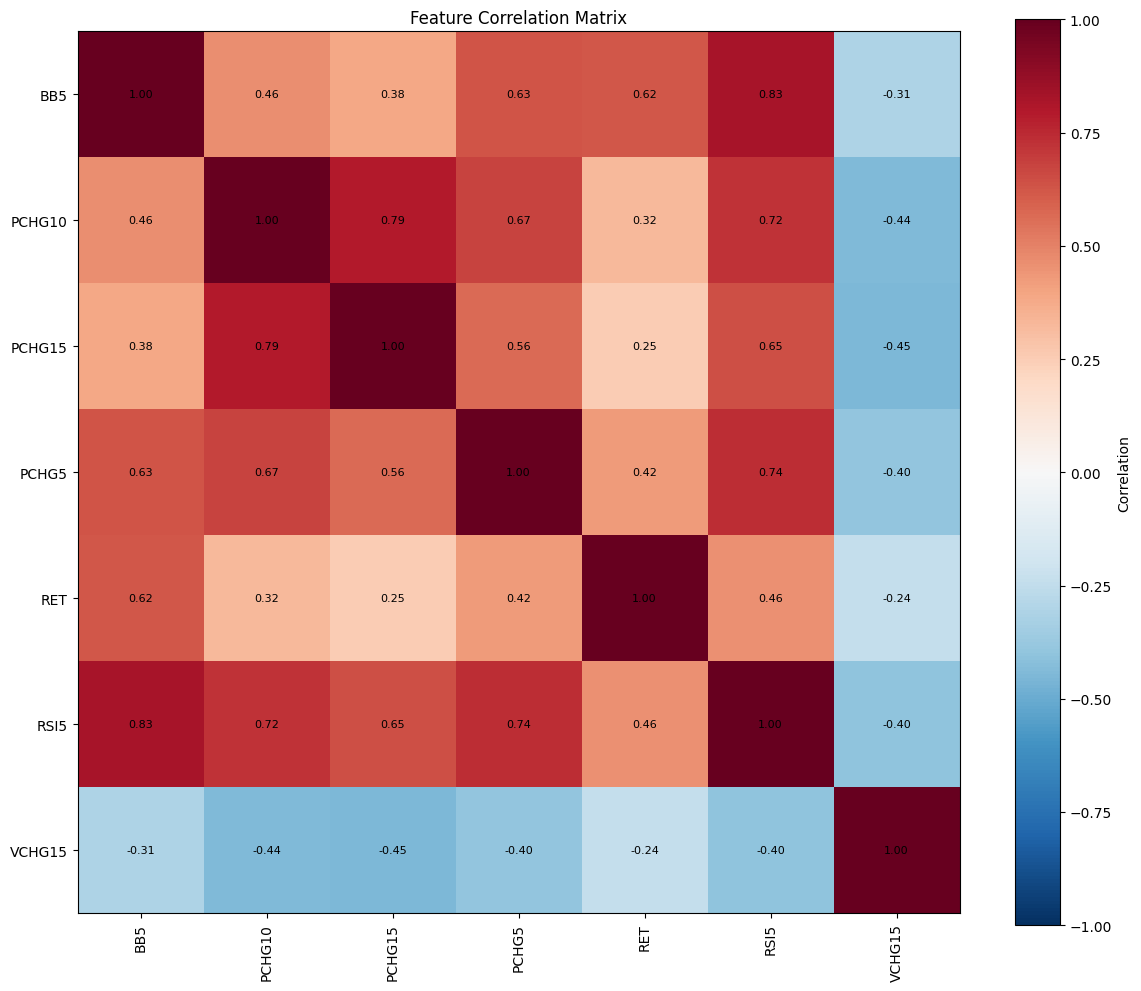

In [7]:
from feature_engineering import FeatureEngineering

FeatureEngineering(
    data_engineering.X_train[data_engineering.features],
    data_engineering.y_train,
    config.feature_selection_methods,
    config.corr_threshold,
    config.n_features,
).plot_correlation_heatmap()

We'll now move to next chapter where I discuss gradient boosting algorithms and employ engineered features in this chapter to predict market moves.

## Q2: Model Building, Tuning, and Benchmarking

In this chapter I focus on modern Gradient Boosting Decision Tree (GBDT) architectures including XGBoost, LightGBM and CatBoost and assess performance of each modelling framework.

### (a) Objective function of GBDT architectures

I'll start with formally defining the mathematical optimization objective function for a GBDT architecture, explicitly highlighting how L1 and L2 regularizations alter the structural tree scores.

#### Additive model and regularized objective

All three libraries build an additive ensemble of regression trees. Even for classification the trees output raw scores (margins) rather than probabilities. At boosting round $t$ the current margin of observation $i$ is updated by the new tree $f_t$ scaled by the learning rate $\eta$:

$$
\hat{z}_{i}^{(t)} = \hat{z}_{i}^{(t-1)} + \eta f_{t}(x_{i}), \qquad f_{t}(x) = w_{q(x)}, \quad q:\mathbb{R}^{d} \to \{1, \dots, T\}, \quad w \in \mathbb{R}^{T}
$$

where $q$ assigns an observation to one of the $T$ leaves of the tree and $w_{j}$ is the score of leaf $j$. The tree is chosen to minimize the regularized objective

$$
\mathcal{L}^{(t)} = \sum_{i=1}^{N} \ell\left(y_{i},\ \hat{z}_{i}^{(t-1)} + f_{t}(x_{i})\right) + \Omega(f_{t})
$$

where $\ell$ is a differentiable loss and $\Omega$ penalizes the complexity of the tree.

**Notation.** $y_{i} \in \{0, 1\}$ is the label of observation $i$ (1 = uptrend). The margin $\hat{z}_{i} \in \mathbb{R}$ is the raw ensemble score, i.e. the sum of the (shrunk) outputs of all trees built so far, $\hat{z}_{i}^{(t-1)} = \hat{z}_{i}^{(0)} + \eta\sum_{k<t} f_{k}(x_{i})$, where $\hat{z}^{(0)}$ is the initial score. It is the predicted log-odds, $\hat{z}_{i} = \ln\frac{p_{i}}{1 - p_{i}}$. The probability of an uptrend is obtained with the sigmoid link

$$
p_{i} = \text{sigm}(\hat{z}_{i}) = \frac{1}{1 + e^{-\hat{z}_{i}}}, \qquad \frac{\partial p_{i}}{\partial \hat{z}_{i}} = p_{i}(1 - p_{i})
$$

and $s_{i} > 0$ is the sample weight (the pipeline uses balanced sample weights computed from the training labels). The weighted logloss of one observation, as a function of its margin, is

$$
\ell_{i}(\hat{z}_{i}) = -s_{i}\left[y_{i}\ln p_{i} + (1 - y_{i})\ln(1 - p_{i})\right] = s_{i}\left[\ln\left(1 + e^{\hat{z}_{i}}\right) - y_{i}\hat{z}_{i}\right]
$$

Differentiating with respect to the margin gives the gradient and the Hessian used by all three libraries:

$$
g_{i} = \frac{\partial \ell_{i}}{\partial \hat{z}_{i}} = s_{i}\left(\frac{e^{\hat{z}_{i}}}{1 + e^{\hat{z}_{i}}} - y_{i}\right) = s_{i}(p_{i} - y_{i}), \qquad h_{i} = \frac{\partial^{2} \ell_{i}}{\partial \hat{z}_{i}^{2}} = s_{i}\,p_{i}(1 - p_{i})
$$

both evaluated at $\hat{z}_{i} = \hat{z}_{i}^{(t-1)}$.

The gradient $g_{i}$ gives the local direction in which the margin should move to lower the loss, while the Hessian $h_{i}$ measures local curvature. It is largest near $p_{i} = 0.5$ and vanishes as $p_{i}$ approaches 0 or 1, so confidently classified observations carry little weight in the tree construction.

#### Second-order approximation and structural tree scores

Regard the per-observation loss as a function of the margin, $\ell_{i}(z)$, and the new tree output $f_{t}(x_{i})$ as a small step $\delta$ away from the current margin $\hat{z}_{i}^{(t-1)}$ (the learning rate $\eta$ is applied afterwards as shrinkage). The second-order Taylor expansion $\ell_{i}(z_{0} + \delta) \approx \ell_{i}(z_{0}) + \ell_{i}'(z_{0})\,\delta + \frac{1}{2}\ell_{i}''(z_{0})\,\delta^{2}$ at $z_{0} = \hat{z}_{i}^{(t-1)}$ and $\delta = f_{t}(x_{i})$ gives

$$
\ell_{i}\left(\hat{z}_{i}^{(t-1)} + f_{t}(x_{i})\right) \approx \ell_{i}\left(\hat{z}_{i}^{(t-1)}\right) + g_{i}f_{t}(x_{i}) + \frac{1}{2}h_{i}f_{t}(x_{i})^{2}
$$

with $g_{i} = s_{i}(p_{i} - y_{i})$ and $h_{i} = s_{i}p_{i}(1 - p_{i})$ from above. Summing over observations and dropping $\sum_{i}\ell_{i}(\hat{z}_{i}^{(t-1)})$, which does not depend on $f_{t}$, gives

$$
\mathcal{L}^{(t)} \approx \sum_{i=1}^{N}\left[g_{i}f_{t}(x_{i}) + \frac{1}{2}h_{i}f_{t}(x_{i})^{2}\right] + \Omega(f_{t})
$$

XGBoost defines the complexity penalty with three components:

$$
\Omega(f) = \gamma T + \frac{1}{2}\lambda\sum_{j=1}^{T}w_{j}^{2} + \alpha\sum_{j=1}^{T}|w_{j}|
$$

where $\gamma$ is a fixed cost per leaf, $\lambda$ is the L2 penalty and $\alpha$ is the L1 penalty on leaf scores. Let $I_{j} = \{i : q(x_{i}) = j\}$ be the observations in leaf $j$, with aggregated derivatives

$$
G_{j} = \sum_{i \in I_{j}} g_{i}, \qquad H_{j} = \sum_{i \in I_{j}} h_{i}
$$

Because the tree output is constant within a leaf, the objective separates by leaf:

$$
\tilde{\mathcal{L}}^{(t)} = \sum_{j=1}^{T}\left[G_{j}w_{j} + \frac{1}{2}(H_{j} + \lambda)w_{j}^{2} + \alpha|w_{j}|\right] + \gamma T
$$

**L2 regularization.** With $\alpha = 0$ the first order condition $G_{j} + (H_{j} + \lambda)w_{j} = 0$ gives the optimal leaf score and the resulting objective:

$$
w_{j}^{*} = -\frac{G_{j}}{H_{j} + \lambda}, \qquad \tilde{\mathcal{L}}^{*} = -\frac{1}{2}\sum_{j=1}^{T}\frac{G_{j}^{2}}{H_{j} + \lambda} + \gamma T
$$

The score is a Newton step $-G_{j}/H_{j}$ multiplied by the shrinkage factor $H_{j}/(H_{j} + \lambda)$. The shrinkage is smooth: scores are pulled towards zero but, unlike under L1, do not become exactly zero unless $G_{j} = 0$ exactly. Each individual gradient $g_{i} = s_{i}(p_{i} - y_{i})$ is never zero because $p_{i} \in (0, 1)$ strictly while $y_{i} \in \{0, 1\}$; $G_{j}$ vanishes only if positive and negative $g_{i}$ cancel within the leaf, which is a non-generic event. The pull is strongest in leaves with small Hessian mass, i.e. leaves supported by few or already confidently classified observations.

**L1 regularization.** The term $\alpha|w_{j}|$ is not differentiable at zero, so the optimality condition is $0 \in G_{j} + (H_{j} + \lambda)w_{j} + \alpha\,\partial|w_{j}|$, where the subdifferential is $\partial|w| = \text{sign}(w)$ for $w \neq 0$ and $\partial|w| = [-1, 1]$ for $w = 0$. The subdifferential of a convex function $f$ at $w_{0}$ is the set of all slopes $c$ of lines through $(w_{0}, f(w_{0}))$ that stay below the graph: $\partial f(w_{0}) = \{c : f(w) \geq f(w_{0}) + c(w - w_{0})\ \forall w\}$. For $w_{0} \neq 0$ the function is differentiable and the only such slope is $\pm 1$. For $w_{0} = 0$ the condition becomes $|w| \geq c\,w$ for all $w$. Taking $w > 0$ gives $c \leq 1$ and taking $w < 0$ gives $c \geq -1$, so every $c \in [-1, 1]$ qualifies. Geometrically, the kink at zero has the left slope $-1$ and the right slope $+1$, and every line through the origin with a slope between them supports the graph from below. At a minimum of a convex function, $0$ must belong to the subdifferential, which gives the optimality condition above. Write $A_{j} = H_{j} + \lambda > 0$ and treat the three cases of the sign of $w_{j}$ separately.

* $w_{j} > 0$: the condition is $G_{j} + A_{j}w_{j} + \alpha = 0$, so $w_{j} = -(G_{j} + \alpha)/A_{j}$. This is consistent with $w_{j} > 0$ only if $G_{j} + \alpha < 0$, i.e. $G_{j} < -\alpha$.
* $w_{j} < 0$: the condition is $G_{j} + A_{j}w_{j} - \alpha = 0$, so $w_{j} = -(G_{j} - \alpha)/A_{j}$. This is consistent with $w_{j} < 0$ only if $G_{j} > \alpha$.
* $w_{j} = 0$: the condition is $0 \in G_{j} + \alpha[-1, 1]$, i.e. $|G_{j}| \leq \alpha$.

The three conditions on $G_{j}$ do not overlap and cover the real line, so exactly one case applies. In the first two cases the score is the L2 solution with the gradient moved towards zero by $\alpha$, that is $G_{j} \mp \alpha = \text{sign}(G_{j})(|G_{j}| - \alpha)$ with $|G_{j}| - \alpha > 0$. In the third case $|G_{j}| - \alpha \leq 0$ and the score is zero. Both situations are written in one formula by the soft-thresholding operator:

$$
w_{j}^{*} = -\frac{T_{\alpha}(G_{j})}{H_{j} + \lambda}, \qquad T_{\alpha}(G) = \text{sign}(G)\max(|G| - \alpha,\ 0)
$$

Equivalently, $w_{j}^{*} = -(G_{j} - \alpha)/(H_{j} + \lambda)$ if $G_{j} > \alpha$, $w_{j}^{*} = -(G_{j} + \alpha)/(H_{j} + \lambda)$ if $G_{j} < -\alpha$ and $w_{j}^{*} = 0$ otherwise. Substituting back, the score of a tree structure becomes

$$
\tilde{\mathcal{L}}^{*} = -\frac{1}{2}\sum_{j=1}^{T}\frac{T_{\alpha}(G_{j})^{2}}{H_{j} + \lambda} + \gamma T
$$

which follows because for $|G_{j}| > \alpha$ the leaf term equals $G_{j}w + \frac{1}{2}A_{j}w^{2} + \alpha|w|$ with $w = -T_{\alpha}(G_{j})/A_{j}$ and $G_{j}w + \alpha|w| = -T_{\alpha}(G_{j})^{2}/A_{j}$, so the term is $-T_{\alpha}(G_{j})^{2}/A_{j} + \frac{1}{2}T_{\alpha}(G_{j})^{2}/A_{j} = -\frac{1}{2}T_{\alpha}(G_{j})^{2}/A_{j}$; for $|G_{j}| \leq \alpha$ the term is $0$. Hence the improvement contributed by a leaf is $\frac{1}{2}T_{\alpha}(G_{j})^{2}/(H_{j} + \lambda)$.

**Leaves with $|G_{j}| \leq \alpha$.** For such a leaf we have $T_{\alpha}(G_{j}) = 0$. Its score is $w_{j}^{*} = 0$, so the tree adds nothing to the margins of the observations in that leaf, and its contribution to the objective is $0$, which is exactly the value of the objective with no leaf-specific correction. The improvement relative to $w_{j} = 0$ is therefore zero: the loss reduction the leaf could offer through its gradient, at most of order $|G_{j}|\,|w|$ for a small step, is smaller than the price $\alpha|w|$ of the L1 penalty for any non-zero $w$, however large $H_{j}$ is. Such a leaf is simply switched off. The three penalties therefore act differently on the tree structure:

* $\lambda$ enlarges the denominator, shrinking every leaf score and every leaf's improvement smoothly.
* $\alpha$ removes $\alpha$ from the gradient mass in the numerator, switching off leaves with weak or noisy signal and producing sparse trees. This matters for daily returns, where the signal-to-noise ratio is low.
* $\gamma$ is a fixed price for adding a leaf, so a split must improve the objective by more than $\gamma$.

For a candidate split of a leaf with statistics $(G, H)$ into left and right children, the gain is

$$
\text{Gain} = \frac{1}{2}\left[\frac{T_{\alpha}(G_{L})^{2}}{H_{L} + \lambda} + \frac{T_{\alpha}(G_{R})^{2}}{H_{R} + \lambda} - \frac{T_{\alpha}(G)^{2}}{H + \lambda}\right] - \gamma
$$

and the split is useful when the gain is positive and both children satisfy the minimum Hessian requirement. For $\alpha = 0$ this reduces to the L2-only gain. As an illustration take a leaf with $G = -3$ and $H = 10$, where the leaf improvement is $S = \frac{1}{2}T_{\alpha}(G)^{2}/(H + \lambda)$:

| $\lambda$ | $\alpha$ | Leaf score $w^{*}$ | Leaf improvement $S$ |
|---|---|---|---|
| 0 | 0 | 0.3000 | 0.4500 |
| 1 | 0 | 0.2727 | 0.4091 |
| 5 | 0 | 0.2000 | 0.3000 |
| 10 | 0 | 0.1500 | 0.2250 |

Increasing $\lambda$ with $\alpha = 0$ lowers the score gradually. Fixing $\lambda = 1$ and increasing $\alpha$:

| $\lambda$ | $\alpha$ | Leaf score $w^{*}$ | Leaf improvement $S$ |
|---|---|---|---|
| 1 | 0 | 0.2727 | 0.4091 |
| 1 | 1 | 0.1818 | 0.1818 |
| 1 | 2 | 0.0909 | 0.0455 |
| 1 | 3 | 0.0000 | 0.0000 |

Here $\alpha = 3 = |G|$ removes the leaf completely.

#### XGBoost

XGBoost uses the objective above without modification. Its penalties are `reg_lambda` ($\lambda$, default 1), `reg_alpha` ($\alpha$, default 0) and `gamma` ($\gamma$), while `min_child_weight` is the minimum Hessian sum $H$ required in a child. Trees are grown level by level up to `max_depth`. The search space in `config.cfg` covers `reg_alpha` $\in \{0, 0.01, 0.1, 1, 5\}$, `reg_lambda` $\in \{1, 5, 10, 20, 50\}$ and `gamma` $\in \{0, 0.1, 0.2, 0.3, 0.4\}$.

#### LightGBM

LightGBM minimizes the same second-order objective with $\Omega(f) = \lambda_{1}\sum_{j}|w_{j}| + \frac{1}{2}\lambda_{2}\sum_{j}w_{j}^{2}$, where $\lambda_{1}$ is `lambda_l1` and $\lambda_{2}$ is `lambda_l2` (both default 0). Its leaf score and split gain have the same form as in XGBoost. LightGBM's Gain is not halved and is compared with `min_gain_to_split` directly, whereas XGBoost compares the same un-halved quantity with $\gamma$ (the $\frac{1}{2}$ appears only in the objective-reduction derivation):

$$
w_{j}^{*} = -\frac{T_{\lambda_{1}}(G_{j})}{H_{j} + \lambda_{2}}, \qquad \text{Gain} = \frac{T_{\lambda_{1}}(G_{L})^{2}}{H_{L} + \lambda_{2}} + \frac{T_{\lambda_{1}}(G_{R})^{2}}{H_{R} + \lambda_{2}} - \frac{T_{\lambda_{1}}(G)^{2}}{H + \lambda_{2}}
$$

There is no explicit $\gamma T$ term. Instead a split is performed only if its gain exceeds `min_gain_to_split` and both children satisfy `min_data_in_leaf` and `min_sum_hessian_in_leaf` (minimum $H$), while the tree size is capped by `num_leaves`. LightGBM grows the tree leaf-wise, expanding the leaf with the largest gain. Because $\lambda_{1}$ and $\lambda_{2}$ enter the gain, they also change which leaf is expanded next: a leaf with $|G| \leq \lambda_{1}$ has zero gain and is never selected.

#### CatBoost

CatBoost penalizes leaf scores with L2 only:

$$
\Omega(f) = \frac{1}{2}\lambda\sum_{j=1}^{T}w_{j}^{2}
$$

where $\lambda$ is `l2_leaf_reg` (default 3). There is no L1 term and no per-leaf cost $\gamma$, so the soft-thresholding above is not available: leaf scores are always shrunk by the factor $H_{j}/(H_{j} + \lambda)$ but never set exactly to zero. CatBoost estimates leaf values with Newton steps (one iteration by default, `leaf_estimation_iterations=1`),

$$
w_{j} = -\frac{G_{j}}{H_{j} + \lambda}
$$

Trees are symmetric (oblivious): every node of a level uses the same split, so a tree of depth $D$ has $T = 2^{D}$ leaves and its complexity is controlled by `depth` rather than by $\gamma$ or a minimum gain. Splits are scored jointly over all leaves of a level using `score_function` (default Cosine). Gradients are computed with the standard (`Plain`) scheme by default; ordered boosting is optional and is discussed in part (b).

#### Summary of regularization controls

| | XGBoost | LightGBM | CatBoost |
|----------------------|--------------------------|----------------------------|------------------------|
| L2 penalty $\lambda$ | `reg_lambda` (default 1) | `lambda_l2` (default 0) | `l2_leaf_reg` (default 3) |
| L1 penalty $\alpha$ | `reg_alpha` (default 0) | `lambda_l1` (default 0) | NA |
| Optimal leaf score | $-T_{\alpha}(G)/(H + \lambda)$ | $-T_{\lambda_{1}}(G)/(H + \lambda_{2})$ | $-G/(H + \lambda)$ |
| Complexity cost of a split | `gamma` | `min_gain_to_split` | none, depth is fixed |
| Minimum Hessian in a child | `min_child_weight` | `min_sum_hessian_in_leaf` | NA |
| Tree shape | level-wise, `max_depth` | leaf-wise, `num_leaves` | symmetric, `depth` |

In all three libraries the trees are trained to minimize the regularized logistic loss, not ROC-AUC. The raw margin $\hat{z}_{i}$ is converted to the probability $p_{i} = \text{sigm}(\hat{z}_{i})$ and a long position is taken when $p_{i} > 0.5$. The regularization strengths are hyperparameters, and ROC-AUC on chronological cross-validation folds is used to select them.

### (b) Hyperparameter tuning

#### Consistent search space

One shared grid (defined in `config.cfg`) is mapped to each library's native parameters, so that every model is searched over the same effective regularization and capacity range. The search is a `RandomizedSearchCV` with $20$ draws, `TimeSeriesSplit` with $5$ folds and a gap of $1$ day (no look-ahead between train and validation), ROC-AUC scoring and the logistic loss in all three libraries.

| Concept | Shared grid | XGBoost | LightGBM | CatBoost | Rationale |
|---|---|---|---|---|---|
| Learning rate | $0.01$ to $0.10$ (10 values) | `learning_rate` | `learning_rate` | `learning_rate` | identical shrinkage $\eta$ |
| Number of trees | $\{100, 200, 300\}$ | `n_estimators` | `n_estimators` | `n_estimators` | same boosting budget |
| Tree capacity | depth $\in \{1,\dots,5\}$ | `max_depth` | `num_leaves` $= 2^{\text{depth}}$ | `depth` | a depth-$D$ tree has at most $2^{D}$ leaves; LightGBM is capped by leaves, not depth |
| L2 penalty $\lambda$ | $\{1, 5, 10, 20, 50\}$ | `reg_lambda` | `lambda_l2` | `l2_leaf_reg` | same $\lambda$ in $H + \lambda$ |
| L1 penalty $\alpha$ | $\{0, 0.01, 0.1, 1, 5\}$ | `reg_alpha` | `lambda_l1` | NA | CatBoost has no L1 term |
| Split cost $\gamma$ | $\{0, 0.1, 0.2, 0.3, 0.4\}$ | `gamma` | `min_gain_to_split` $= \gamma$ | NA | both compare $S_{L} + S_{R} - S$ with the threshold (see below) |
| Minimum Hessian in a child | $\{1, 3, 5, 7\}$ | `min_child_weight` | `min_sum_hessian_in_leaf` | NA | same quantity $H_{\text{child}}$ |
| Feature subsampling | $\{0.3, 0.4, 0.5, 0.7\}$ | `colsample_bytree` | `colsample_bytree` | `rsm` | fraction of features per tree (CatBoost: per split) |

Parameters that a library does not have are left out rather than approximated, and the CatBoost grid is therefore smaller. Thread count and verbosity are set per library and are not tuned.

#### Leaf-wise (LightGBM) versus level-wise (XGBoost) growth

For a node with gradient and Hessian sums $(G, H)$ define the node score $S(G, H) = T_{\alpha}(G)^{2}/(H + \lambda)$. Splitting node $\ell$ into children $L, R$ reduces the regularized objective by

$$
\Delta_{\ell} = \frac{1}{2}\left[S(G_{L}, H_{L}) + S(G_{R}, H_{R}) - S(G_{\ell}, H_{\ell})\right] - \gamma .
$$

The implementations both test the un-halved quantity $\text{Gain}_{\ell} = S_{L} + S_{R} - S_{\ell}$ against their threshold ($\gamma$ in XGBoost, `min_gain_to_split` in LightGBM), which was verified numerically on a toy tree where both libraries remove the split at the same gain. This is why the same value is used for both.

- **Level-wise (XGBoost).** At depth $d$ the frontier $\mathcal{F}_{d}$ contains all nodes of that depth, and every node with an admissible split is split, $\mathcal{F}_{d+1} = \{L_{\ell}, R_{\ell} : \ell \in \mathcal{F}_{d},\ \text{Gain}_{\ell}^{*} > \gamma\}$, until $d = $ `max_depth`. The tree is balanced and complexity is bounded by $2^{D}$ leaves.
- **Leaf-wise (LightGBM).** With the current leaf set $\mathcal{L}_{k}$ ($|\mathcal{L}_{k}| = k$) the next split is applied to the single leaf with the largest best-split gain,

$$
\ell^{*} = \arg\max_{\ell \in \mathcal{L}_{k}}\ \max_{s}\ \text{Gain}_{\ell}(s), \qquad \mathcal{L}_{k+1} = (\mathcal{L}_{k}\setminus\{\ell^{*}\}) \cup \{L_{\ell^{*}}, R_{\ell^{*}}\},
$$

  and growth stops when $k = $ `num_leaves` or $\max_{\ell}\text{Gain}_{\ell} \leq$ `min_gain_to_split`.

For the same number of leaves $T$ the leaf-wise tree greedily maximizes the total reduction $\sum_{\text{splits}}\text{Gain}$, so its training loss is never higher than that of the level-wise tree, but it can create deep, unbalanced branches that fit small, noisy regions, which is why `num_leaves` is capped (and set to $2^{\text{depth}}$ here) and `min_sum_hessian_in_leaf` is used. With a leaf budget of $2^{D}$ the two coincide in the limit of a full tree.

#### CatBoost target statistics and look-ahead bias

A categorical feature is replaced by a target statistic (TS). The naive (greedy) version $\hat{x}_{i} = \frac{\sum_{j}\mathbf{1}[x_{j} = x_{i}]\,y_{j} + a P}{\sum_{j}\mathbf{1}[x_{j} = x_{i}] + a}$ uses $y_{i}$ itself, so the feature leaks the target and causes a conditional shift between train and test. CatBoost draws a permutation $\sigma$ of the observations (in time series, the chronological order, enabled with `has_time=True`) and uses only the observations that precede $i$:

$$
\hat{x}_{i} = \frac{\sum_{j \in D_{i}}\mathbf{1}[x_{j} = x_{i}]\,y_{j} + a\,P}{\sum_{j \in D_{i}}\mathbf{1}[x_{j} = x_{i}] + a}, \qquad D_{i} = \{ j : \sigma(j) < \sigma(i) \},
$$

where $P$ is a prior (for example the mean of $y$) and $a > 0$ is the prior weight. Because $y_{i}$ and all later targets are excluded, $\hat{x}_{i}$ is a function of the past only. The same idea is used for the gradients: under ordered boosting the gradient of observation $i$ is computed from a supporting model $M_{\sigma(i)-1}$ trained only on observations before $i$,

$$
g_{i} = \frac{\partial \ell\big(y_{i}, M_{\sigma(i)-1}(x_{i})\big)}{\partial \hat{z}}, \qquad h_{i} = \frac{\partial^{2} \ell\big(y_{i}, M_{\sigma(i)-1}(x_{i})\big)}{\partial \hat{z}^{2}},
$$

so that the residual of $i$ is not computed by a model that has already seen $y_{i}$, which removes the prediction shift of standard gradient boosting.

In this pipeline all features are numeric, CatBoost runs with its default `boosting_type='Plain'` and `has_time` is not set, so neither the ordered target statistics nor ordered boosting is active. The mechanism above is the reason CatBoost is robust on small samples with categorical features, but its measured performance here comes from the symmetric trees and L2 shrinkage. The temporal protection against look-ahead in this exam comes from the chronological train/test split and the gapped `TimeSeriesSplit`.

#### Selected hyperparameters

In [8]:
for boosting_algo in config.boosting_algorithms:
    display(Markdown(f"**Best parameters for {boosting_algo}:**"))
    show_table(pd.DataFrame(best_parameters[boosting_algo], index=[0]), floatfmt="g")

**Best parameters for xgboost:**

|   reg_lambda |   reg_alpha |   n_estimators |   min_child_weight |   max_depth |   learning_rate |   gamma |   colsample_bytree |
|-------------:|------------:|---------------:|-------------------:|------------:|----------------:|--------:|-------------------:|
|           20 |        0.01 |            100 |                  5 |           2 |            0.02 |     0.3 |                0.4 |

**Best parameters for lightgbm:**

|   num_leaves |   n_estimators |   min_sum_hessian_in_leaf |   min_gain_to_split |   learning_rate |   lambda_l2 |   lambda_l1 |   colsample_bytree |
|-------------:|---------------:|--------------------------:|--------------------:|----------------:|------------:|------------:|-------------------:|
|            2 |            200 |                         5 |                 0.2 |            0.02 |          50 |         0.1 |                0.7 |

**Best parameters for catboost:**

|   rsm |   n_estimators |   learning_rate |   l2_leaf_reg |   depth |
|------:|---------------:|----------------:|--------------:|--------:|
|   0.5 |            300 |            0.01 |             5 |       1 |

### (c) Model metrics and trading strategies

**Model metrics:**

|                         |   xgboost |   lightgbm |   catboost |
|:------------------------|----------:|-----------:|-----------:|
| train_accuracy          |    0.5546 |     0.5463 |     0.5481 |
| test_accuracy           |    0.5667 |     0.5369 |     0.5595 |
| train_balanced_accuracy |    0.5815 |     0.5746 |     0.5716 |
| test_balanced_accuracy  |    0.5803 |     0.5578 |     0.5749 |
| roc_auc                 |    0.5876 |     0.5893 |     0.5905 |
| f1                      |    0.4916 |     0.4750 |     0.4875 |
| precision               |    0.4065 |     0.3843 |     0.4009 |
| recall                  |    0.6219 |     0.6219 |     0.6219 |

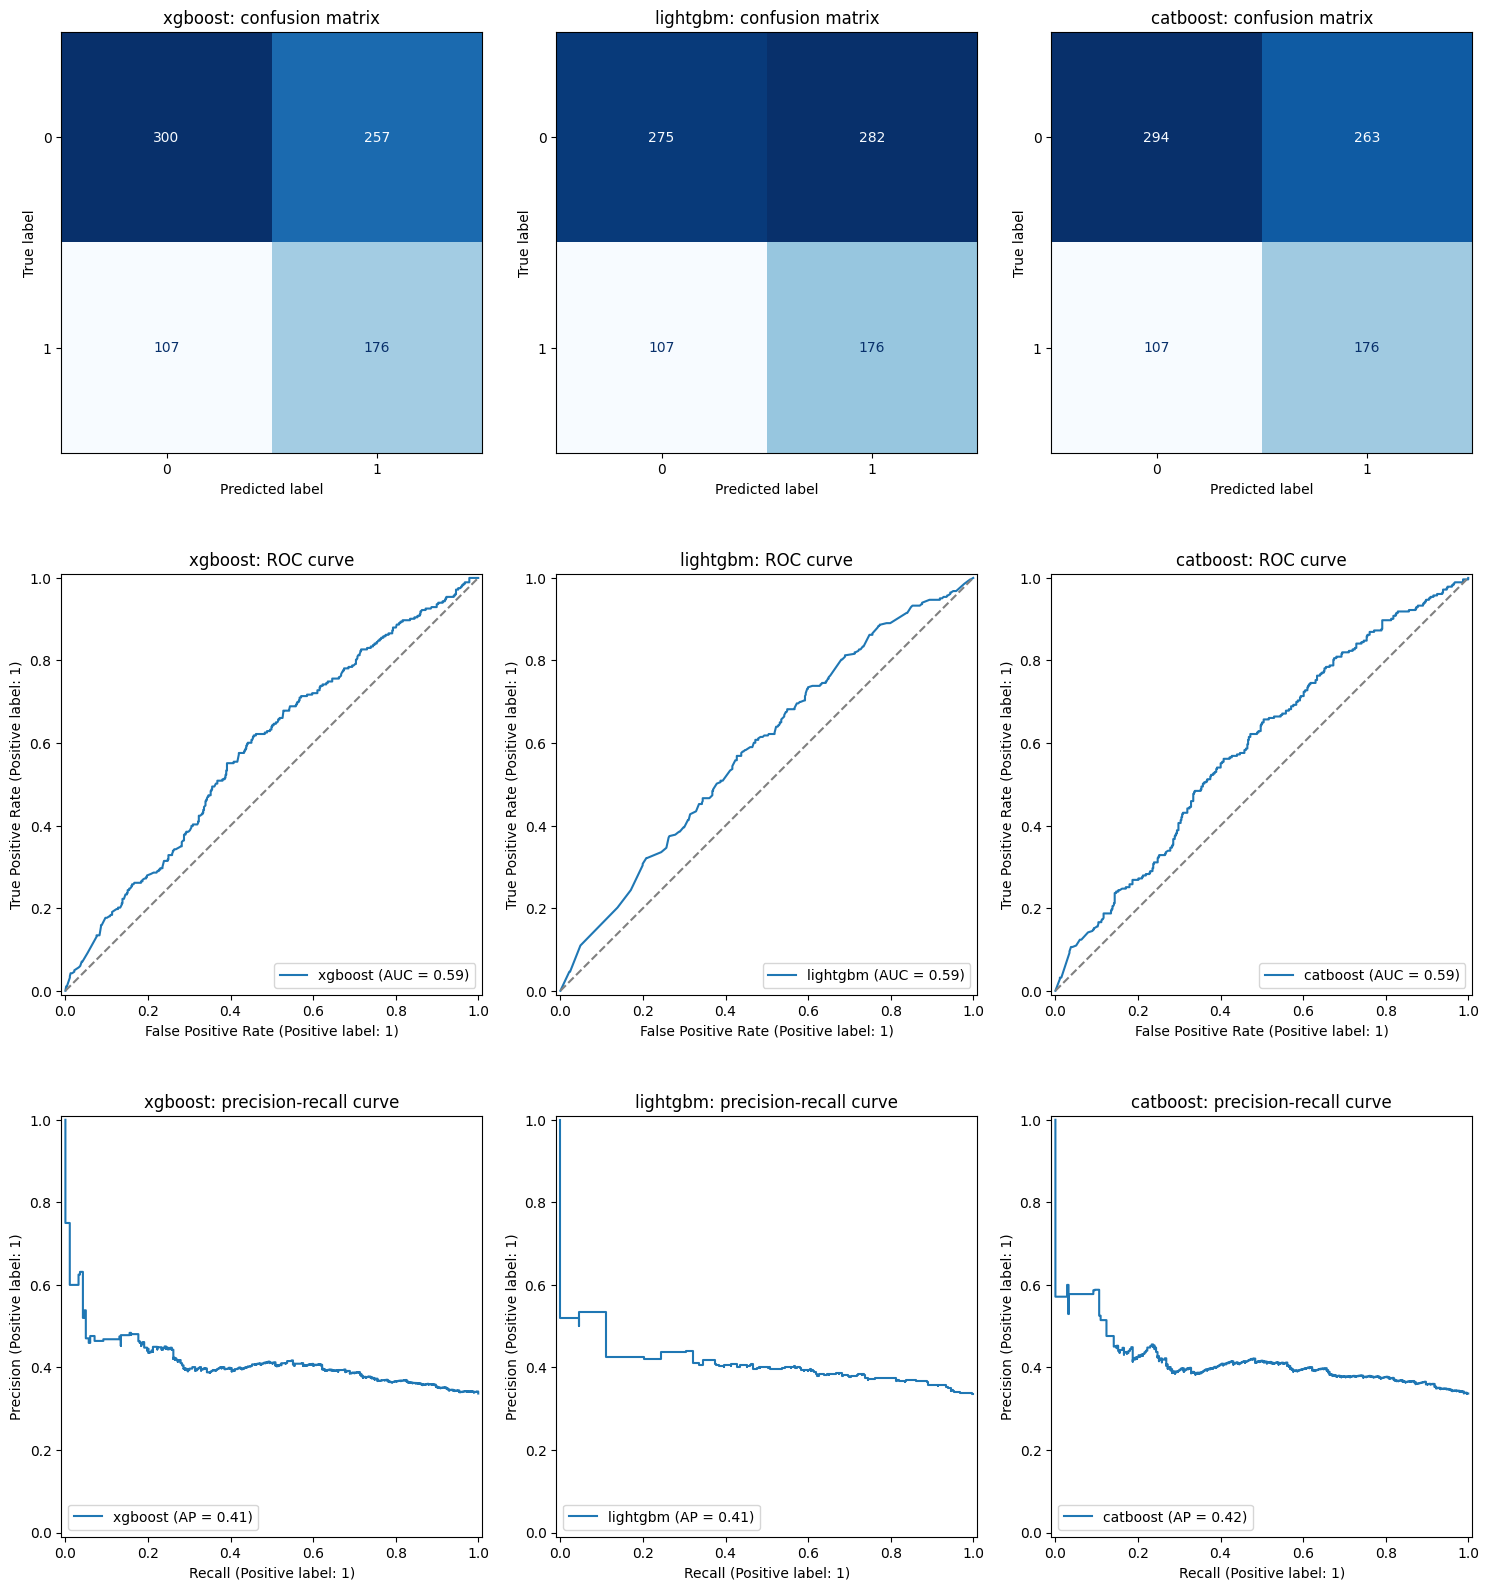

In [9]:
display(Markdown("**Model metrics:**"))
show_table(pd.DataFrame(metrics), index=True)

MLClassifier.plot_evaluation_grid(classifiers)

#### Metric definitions

All metrics are computed out-of-sample on the final 20% of the chronologically ordered data ($N = 840$ days). The positive class $y = 1$ is an uptrend label and the classifier output $\hat{y} = \mathbf{1}[p > 0.5]$ is used for threshold-based metrics. From the confusion matrix

$$
\begin{pmatrix} TN & FP \\ FN & TP \end{pmatrix}, \qquad TP + FP + FN + TN = N,
$$

we define

$$
\text{Accuracy} = \frac{TP + TN}{N}, \qquad \text{Precision} = \frac{TP}{TP + FP}, \qquad \text{Recall (TPR)} = \frac{TP}{TP + FN},
$$

$$
\text{Specificity (TNR)} = \frac{TN}{TN + FP}, \qquad \text{FPR} = \frac{FP}{FP + TN}, \qquad F_{1} = \frac{2\,\text{Precision}\cdot\text{Recall}}{\text{Precision} + \text{Recall}},
$$

$$
\text{Balanced accuracy} = \frac{1}{2}\left(\text{TPR} + \text{TNR}\right).
$$

Balanced accuracy is reported because the classes are imbalanced (the base rate of $y = 1$ in the test set is $283/840 = 0.337$), so plain accuracy rewards predicting the majority class. The classification report gives precision, recall and $F_{1}$ for each class $c$ (treating $c$ as positive), together with the macro average $\frac{1}{2}\sum_{c}m_{c}$ and the support-weighted average $\sum_{c}\frac{n_{c}}{N}m_{c}$.

The ROC curve plots $\text{TPR}(\tau)$ against $\text{FPR}(\tau)$ as the threshold $\tau$ on $p$ varies, and the precision-recall curve plots $\text{Precision}(\tau)$ against $\text{Recall}(\tau)$. The area under the ROC curve is threshold-free and equals the probability that a random positive is ranked above a random negative (Mann-Whitney form):

$$
\text{AUC} = \int_{0}^{1}\text{TPR}\,d(\text{FPR}) = \frac{1}{n_{+}n_{-}}\sum_{i:\,y_{i}=1}\;\sum_{k:\,y_{k}=0}\left(\mathbf{1}[p_{i} > p_{k}] + \tfrac{1}{2}\mathbf{1}[p_{i} = p_{k}]\right),
$$

with $\text{AUC} = 0.5$ for a random ranking. Overfitting is measured by the train-test gap $\text{BA}_{\text{train}} - \text{BA}_{\text{test}}$ of balanced accuracy. For trading, precision is the hit rate of executed long trades, and the lift over the base rate is $\text{Precision}/\pi_{+}$ with $\pi_{+} = 0.337$.

In [10]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

display(Markdown("**Classification reports (out-of-sample):**"))
for algo, clf in classifiers.items():
    y_pred = clf.model.predict(clf.X_test)
    rep = pd.DataFrame(classification_report(clf.y_test, y_pred, output_dict=True)).T
    rep["support"] = rep["support"].astype(int)
    display(Markdown(f"*{algo}*"))
    show_table(rep, floatfmt=".4f", index=True)

rng = np.random.default_rng(42)
rows, base_rate = {}, None
for algo, clf in classifiers.items():
    y_true = np.asarray(clf.y_test)
    p = clf.model.predict_proba(clf.X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_true, (p > 0.5).astype(int)).ravel()
    base_rate = y_true.mean()
    aucs = []
    for _ in range(1000):
        idx = rng.integers(0, len(y_true), len(y_true))
        aucs.append(roc_auc_score(y_true[idx], p[idx]))
    lo, hi = np.percentile(aucs, [2.5, 97.5])
    s = clf.search
    best = s.best_index_
    rows[algo] = {
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "Precision lift vs base rate": tp / (tp + fp) / base_rate,
        "Test ROC-AUC": roc_auc_score(y_true, p),
        "AUC 95% CI low": lo, "AUC 95% CI high": hi,
        "CV ROC-AUC mean": s.cv_results_["mean_test_score"][best],
        "CV ROC-AUC std": s.cv_results_["std_test_score"][best],
        "Train-test balanced acc. gap": metrics[algo]["train_balanced_accuracy"] - metrics[algo]["test_balanced_accuracy"],
        "Position changes": int((clf.signal["Signal"].diff().abs() > 0).sum()),
    }
display(Markdown("**Execution trade-off and stability:**"))
show_table(pd.DataFrame(rows), floatfmt=".4f", index=True)

**Classification reports (out-of-sample):**

*xgboost*

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |      0.7371 |   0.5386 |     0.6224 |  557.0000 |
| 1            |      0.4065 |   0.6219 |     0.4916 |  283.0000 |
| accuracy     |      0.5667 |   0.5667 |     0.5667 |    0.0000 |
| macro avg    |      0.5718 |   0.5803 |     0.5570 |  840.0000 |
| weighted avg |      0.6257 |   0.5667 |     0.5783 |  840.0000 |

*lightgbm*

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |      0.7199 |   0.4937 |     0.5857 |  557.0000 |
| 1            |      0.3843 |   0.6219 |     0.4750 |  283.0000 |
| accuracy     |      0.5369 |   0.5369 |     0.5369 |    0.0000 |
| macro avg    |      0.5521 |   0.5578 |     0.5304 |  840.0000 |
| weighted avg |      0.6068 |   0.5369 |     0.5484 |  840.0000 |

*catboost*

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |      0.7332 |   0.5278 |     0.6138 |  557.0000 |
| 1            |      0.4009 |   0.6219 |     0.4875 |  283.0000 |
| accuracy     |      0.5595 |   0.5595 |     0.5595 |    0.0000 |
| macro avg    |      0.5670 |   0.5749 |     0.5507 |  840.0000 |
| weighted avg |      0.6212 |   0.5595 |     0.5712 |  840.0000 |

**Execution trade-off and stability:**

|                              |   xgboost |   lightgbm |   catboost |
|:-----------------------------|----------:|-----------:|-----------:|
| TP                           |  176.0000 |   176.0000 |   176.0000 |
| FP                           |  257.0000 |   282.0000 |   263.0000 |
| FN                           |  107.0000 |   107.0000 |   107.0000 |
| TN                           |  300.0000 |   275.0000 |   294.0000 |
| Precision lift vs base rate  |    1.2065 |     1.1406 |     1.1900 |
| Test ROC-AUC                 |    0.5876 |     0.5893 |     0.5905 |
| AUC 95% CI low               |    0.5458 |     0.5469 |     0.5470 |
| AUC 95% CI high              |    0.6256 |     0.6301 |     0.6282 |
| CV ROC-AUC mean              |    0.5767 |     0.5836 |     0.5886 |
| CV ROC-AUC std               |    0.0328 |     0.0399 |     0.0411 |
| Train-test balanced acc. gap |    0.0013 |     0.0168 |    -0.0033 |
| Position changes             |  188.0000 |   225.0000 |   184.0000 |

#### Interpretation and recommendation

**Predictive power.** All three models rank days only slightly better than chance: test ROC-AUC is $0.588$ (XGBoost), $0.589$ (LightGBM) and $0.591$ (CatBoost), with bootstrap 95% intervals of about $[0.55, 0.63]$ that exclude $0.5$ but overlap almost completely. Paired bootstrap differences in AUC are below $0.003$ with intervals containing zero, so the ranking quality of the three frameworks is statistically indistinguishable. The edge is real but small, which is expected for a one-day-ahead equity signal.

**Precision-recall trade-off.** Recall is identical ($0.622$, $TP = 176$, $FN = 107$) for all models, so they differ only in false positives: XGBoost $257$, CatBoost $263$, LightGBM $282$. Precision is therefore $0.407$, $0.401$ and $0.384$, a lift of about $1.2\times$ over the $0.337$ base rate. For execution, each false positive is a long position on a day without an uptrend, so XGBoost and CatBoost trade more efficiently than LightGBM, which has the lowest accuracy ($0.537$), balanced accuracy ($0.558$) and $F_{1}$ ($0.475$). The models are tilted towards recall (they buy often, about $52$-$55\%$ of days) and are mostly right about avoiding the weak days: class-0 precision is $0.72$-$0.74$.

**Stability and risk.** XGBoost has the smallest cross-validation AUC dispersion and the smallest train-test gap; CatBoost has the highest CV AUC ($0.589$) but also the largest fold dispersion. CatBoost switches position the least ($184$ changes versus $188$ for XGBoost and about $225$ for LightGBM), which matters once transaction costs are included, and LightGBM has the deepest drawdown ($-0.202$ against $-0.194$ and $-0.197$ log points). The trading assessment below shows that this translates into the best Sharpe, Sortino and cumulative log return for CatBoost ($0.92$, $1.37$, $0.40$) versus XGBoost ($0.64$, $0.93$, $0.28$) and LightGBM ($0.61$, $0.89$, $0.27$).

**Recommendation.** CatBoost is the preferred algorithm: it has the highest out-of-sample and cross-validated AUC, the lowest turnover and the best risk-adjusted strategy performance, using the simplest model (depth-1 symmetric trees with L2 shrinkage). Because the statistical differences in AUC are not significant, the choice rests mainly on operational and economic grounds, and XGBoost is a close second with the best stability metrics and the highest precision. LightGBM is the weakest here and is not recommended. The conclusion should be read with the caveat in the next section: none of the model strategies beats Buy-and-Hold on a risk-adjusted basis.

### Trading strategy assessment

Each model is converted into a long/flat strategy: the position on day $t$ is $s_{t} = \hat{y}_{t} \in \{0, 1\}$ and the strategy log return is $r^{S}_{t+1} = s_{t}\,r_{t+1}$, where $r_{t+1} = \ln(P_{t+1}/P_{t})$ is the SPY log return. The benchmark is Buy-and-Hold, $s_{t} \equiv 1$. Results are for the out-of-sample period only and, unless stated, ignore transaction costs. With $\bar{r}$ and $\sigma$ the mean and standard deviation of daily returns and $252$ trading days per year:

$$
\text{Sharpe} = \sqrt{252}\,\frac{\bar{r}}{\sigma}, \qquad \text{Sortino} = \sqrt{252}\,\frac{\bar{r}}{\sigma_{d}}, \quad \sigma_{d}^{2} = \frac{1}{n}\sum_{t}\min(r_{t}, 0)^{2},
$$

$$
    \text{MaxDD} = \min_{t}\left(C_{t} - \max_{u \leq t}C_{u}\right), \quad C_{t} = \sum_{k \leq t}r_{k}, \qquad \text{Calmar} = \frac{252\,\bar{r}}{|\text{MaxDD}|}.
$$

Cumulative return $C_{T}$ and drawdown are therefore expressed in log points, consistent with the `Total_Return` and `Max_Drawdown` figures computed by the pipeline.

The Sharpe differences are tested with a paired block bootstrap (20-day blocks, 2000 resamples), which preserves serial dependence, and a cost sensitivity charges $1$ bp per position change.

|                       |   Buy-and-Hold |   xgboost |   lightgbm |   catboost |
|:----------------------|---------------:|----------:|-----------:|-----------:|
| Cumulative log return |         0.5987 |    0.2810 |     0.2707 |     0.3960 |
| Annualised return     |         0.1796 |    0.0843 |     0.0812 |     0.1188 |
| Annualised volatility |         0.1483 |    0.1315 |     0.1323 |     0.1298 |
| Sharpe                |         1.2112 |    0.6412 |     0.6138 |     0.9153 |
| Sortino               |         1.7787 |    0.9282 |     0.8869 |     1.3668 |
| Max drawdown          |        -0.2107 |   -0.1940 |    -0.2017 |    -0.1969 |
| Calmar                |         0.8524 |    0.4345 |     0.4025 |     0.6032 |
| Time in market        |         1.0000 |    0.5155 |     0.5452 |     0.5226 |
| Position changes      |         0.0000 |  188.0000 |   225.0000 |   184.0000 |
| Sharpe (1bp cost)     |         1.2112 |    0.5982 |     0.5627 |     0.8727 |

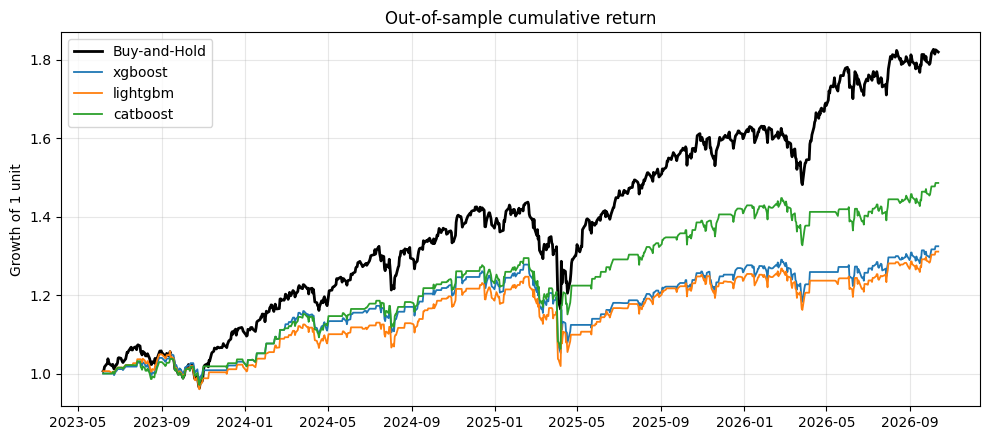

**Paired block bootstrap of Sharpe(strategy) minus Sharpe(Buy-and-Hold):**

|                    |   xgboost |   lightgbm |   catboost |
|:-------------------|----------:|-----------:|-----------:|
| Sharpe diff vs B&H |    -0.570 |     -0.597 |     -0.296 |
| 95% CI low         |    -1.131 |     -1.133 |     -0.891 |
| 95% CI high        |    -0.006 |     -0.099 |      0.216 |
| P(diff > 0)        |     0.024 |      0.011 |      0.146 |

In [11]:
import matplotlib.pyplot as plt

ann = 252

def perf(r, pos=None, cost=0.0):
    r = np.asarray(r, dtype=float)
    if pos is not None and cost:
        r = r - cost * np.abs(np.diff(pos, prepend=pos[0]))
    wealth = np.cumsum(r)
    dd = (wealth - np.maximum.accumulate(wealth)).min()
    downside = np.sqrt(np.mean(np.minimum(r, 0) ** 2))
    return {
        "Cumulative log return": wealth[-1],
        "Annualised return": ann * r.mean(),
        "Annualised volatility": np.sqrt(ann) * r.std(ddof=1),
        "Sharpe": np.sqrt(ann) * r.mean() / r.std(ddof=1),
        "Sortino": np.sqrt(ann) * r.mean() / downside,
        "Max drawdown": dd,
        "Calmar": ann * r.mean() / abs(dd),
    }

first = next(iter(classifiers.values())).signal
ret = first["tomorrow_returns"].to_numpy()
table = {"Buy-and-Hold": {**perf(ret), "Time in market": 1.0, "Position changes": 0, "Sharpe (1bp cost)": perf(ret)["Sharpe"]}}
series = {"Buy-and-Hold": ret}
for algo, clf in classifiers.items():
    sig = clf.signal
    pos = sig["Signal"].to_numpy()
    r = sig["Strategy"].to_numpy()
    table[algo] = {**perf(r), "Time in market": pos.mean(), "Position changes": int(np.abs(np.diff(pos)).sum()),
                   "Sharpe (1bp cost)": perf(r, pos, 1e-4)["Sharpe"]}
    series[algo] = r
show_table(pd.DataFrame(table), floatfmt=".4f", index=True)

fig, ax = plt.subplots(figsize=(10, 4.5))
dates = first.index
for name, r in series.items():
    ax.plot(dates, np.exp(np.cumsum(r)), label=name, lw=2 if name == "Buy-and-Hold" else 1.3, color="black" if name == "Buy-and-Hold" else None)
ax.set_ylabel("Growth of 1 unit"); ax.set_title("Out-of-sample cumulative return"); ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()

rng = np.random.default_rng(42)
n, block, B = len(ret), 20, 2000
starts_n = int(np.ceil(n / block))
def sharpe(x): return np.sqrt(ann) * x.mean() / x.std(ddof=1)
diffs = {a: [] for a in classifiers}
for _ in range(B):
    idx = np.concatenate([np.arange(s, s + block) for s in rng.integers(0, n - block + 1, starts_n)])[:n]
    for a in classifiers:
        diffs[a].append(sharpe(series[a][idx]) - sharpe(ret[idx]))
boot = {a: {"Sharpe diff vs B&H": table[a]["Sharpe"] - table["Buy-and-Hold"]["Sharpe"],
            "95% CI low": np.percentile(d, 2.5), "95% CI high": np.percentile(d, 97.5), "P(diff > 0)": np.mean(np.array(d) > 0)}
        for a, d in diffs.items()}
display(Markdown("**Paired block bootstrap of Sharpe(strategy) minus Sharpe(Buy-and-Hold):**"))
show_table(pd.DataFrame(boot), floatfmt=".3f", index=True)

#### Conclusion

Buy-and-Hold on SPY had a strong out-of-sample period (Sharpe about $1.21$, cumulative log return about $0.60$), and none of the model-driven strategies beats it on Sharpe, Sortino or cumulative return. The models are long only about half of the time, so they give up much of the equity premium. What they do deliver is lower volatility ($13.0$-$13.2\%$ against $14.8\%$) and a slightly shallower maximum drawdown for XGBoost and CatBoost ($-0.194$ and $-0.197$ against $-0.211$ log points).

Among the models, CatBoost is clearly best (Sharpe $0.92$ versus $0.64$ and $0.61$), which supports the recommendation in (c). The block bootstrap shows that XGBoost and LightGBM are significantly worse than Buy-and-Hold on Sharpe, whereas for CatBoost the difference is not significant (the interval contains $0$), so CatBoost is statistically no worse than the benchmark but also not better. The ranking survives a $1$ bp cost per position change because CatBoost also trades the least.

The final recommendation is therefore CatBoost, used as a risk-reducing timing overlay rather than as a standalone source of excess return. The caveats are a single out-of-sample period, no costs or slippage beyond the sensitivity above, and AUC differences between the models that are not statistically significant.